# Karate Club | Spectral Modularity Lab

> **DSC212 · Graph Theory Module**  
> A reproducible investigation of how spectral modularity reveals communities in Zachary's karate club.

## Notebook map

| Phase | What happens |
|---|---|
| **01 · Foundation** | Load the unweighted network and verify the modularity matrix. |
| **02 · Spectral engine** | Recursively test eigenvectors and accept only positive-gain splits. |
| **03 · Community gallery** | Compare the fixed-layout graph after every accepted split. |
| **04 · Diagnostics** | Track four NetworkX metrics for every node across iterations. |
| **05 · Takeaways** | Interpret centrality changes and the final partition. |

The notebook is intentionally organized as an experiment: **inputs → decision rule → evidence → interpretation**.

## 01 · Foundation — the score we are optimizing

For adjacency matrix $A$, degree vector $k$, and $m$ edges, the modularity matrix is

$$B = A - \frac{kk^\top}{2m}.$$

For a two-way label vector $s \in \{-1,+1\}^n$,
$$Q = \frac{1}{4m}s^\top Bs.$$

A leading eigenvector gives a relaxed sign split. For a candidate community $C$, the corrected restricted matrix
$$B_C = B[C,C] - \operatorname{diag}(B[C,C]\mathbf{1})$$
keeps the restricted rows balanced, so the positive-eigenvalue stopping rule remains meaningful.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
from IPython.display import display

SEED = 212
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 6), 'axes.titlesize': 13, 'font.size': 10})

# NetworkX stores this classic graph with labels 0--33; the assignment uses 1--34.
# The handout defines an unweighted graph, so discard the source edge weights.
G = nx.karate_club_graph()
G = nx.relabel_nodes(G, {node: node + 1 for node in G.nodes()})
nx.set_edge_attributes(G, 1.0, 'weight')
nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float, weight=None)
degrees = A.sum(axis=1)
B = A - np.outer(degrees, degrees) / (2 * m)
node_index = {node: index for index, node in enumerate(nodes)}
layout = nx.shell_layout(G, nlist=[[1, 34], [node for node in nodes if node not in {1, 34}]], scale=1.0)

print(f'Karate Club graph: {n} nodes, {m} edges')
print(f'Modularity matrix shape: {B.shape}')
print(f'Symmetry check: {np.allclose(B, B.T)}')
print(f'Row-sum check: {np.allclose(B.sum(axis=1), 0)}')

Karate Club graph: 34 nodes, 78 edges
Modularity matrix shape: (34, 34)
Symmetry check: True
Row-sum check: True


### Network snapshot

The handout specifies the classic **unweighted** graph. Node IDs are shown as 1–34 to match the assignment.

In [2]:
degree_summary = pd.Series(degrees, index=nodes, name='degree')
print(f'Nodes: {n} | Edges: {m} | Density: {nx.density(G):.4f}')
print(f'Degree range: {int(degree_summary.min())}–{int(degree_summary.max())}')
display(degree_summary.sort_values(ascending=False).head(8).to_frame())

Nodes: 34 | Edges: 78 | Density: 0.1390
Degree range: 1–17


,degree
34,17.0
1,16.0
33,12.0
3,10.0
2,9.0
4,6.0
32,6.0
24,5.0


## 02 · Spectral engine — recursive decisions

Each queued community is tested independently. The sign of the leading eigenvector proposes two groups; the split is kept only if both groups exist **and** the discrete modularity score increases. This makes the implementation faithful to the spectral idea while guarding against an unhelpful sign rounding.

In [3]:
def modularity_score(communities):
    labels = {}
    for community_id, community in enumerate(communities):
        for node in community:
            labels[node] = community_id
    score = 0.0
    for i, node_i in enumerate(nodes):
        for j, node_j in enumerate(nodes):
            if labels[node_i] == labels[node_j]:
                score += B[i, j]
    return score / (2 * m)

def corrected_restricted_matrix(community):
    indices = [node_index[node] for node in community]
    block = B[np.ix_(indices, indices)]
    return block - np.diag(block.sum(axis=1))

def sign_split(community, eigenvector):
    positive = [node for node, value in zip(community, eigenvector) if value > 1e-12]
    negative = [node for node, value in zip(community, eigenvector) if value <= 1e-12]
    if not positive or not negative:
        return None
    return sorted(positive), sorted(negative)

def recursive_spectral_partition(graph_nodes):
    initial = [sorted(graph_nodes)]
    records = [{'iteration': 0, 'communities': [community.copy() for community in initial], 'split': None, 'lambda': None, 'gain': 0.0}]
    queue = deque([sorted(graph_nodes)])
    communities = initial
    iteration = 0

    while queue:
        community = queue.popleft()
        if len(community) < 2:
            continue
        restricted = corrected_restricted_matrix(community)
        eigenvalues, eigenvectors = np.linalg.eigh(restricted)
        leading_value = float(eigenvalues[-1])
        leading_vector = eigenvectors[:, -1]
        split = sign_split(community, leading_vector)
        if leading_value <= 1e-10 or split is None:
            continue

        left, right = split
        candidate = [other for other in communities if other != community] + [left, right]
        gain = modularity_score(candidate) - modularity_score(communities)
        if gain <= 1e-10:
            continue

        communities = sorted(candidate, key=lambda group: (min(group), len(group)))
        iteration += 1
        records.append({'iteration': iteration, 'communities': [group.copy() for group in communities], 'split': (left, right), 'lambda': leading_value, 'gain': gain})
        queue.extend([left, right])

    return communities, records

final_communities, split_records = recursive_spectral_partition(nodes)
print(f'Accepted splits: {len(split_records) - 1}')
print(f'Final communities: {len(final_communities)}')
for index, community in enumerate(final_communities, start=1):
    print(f'Community {index}: {community}')
print('\nAccepted split decisions:')
for record in split_records[1:]:
    print(f"Iteration {record['iteration']}: lambda_1 = {record['lambda']:.4f}, gain = {record['gain']:.4f}")
print(f'Final modularity Q = {modularity_score(final_communities):.4f}')

Accepted splits: 3
Final communities: 4
Community 1: [1, 5, 6, 7, 11, 12, 17]
Community 2: [2, 3, 4, 8, 13, 14, 18, 20, 22]
Community 3: [9, 10, 15, 16, 19, 21, 23, 27, 30, 31, 33, 34]
Community 4: [24, 25, 26, 28, 29, 32]

Accepted split decisions:
Iteration 1: lambda_1 = 4.9771, gain = 0.3715
Iteration 2: lambda_1 = 1.1785, gain = 0.0012
Iteration 3: lambda_1 = 0.8594, gain = 0.0207
Final modularity Q = 0.3934


### Decision log

The table below makes the stopping logic auditable: every accepted split has a positive leading eigenvalue and a positive realized gain.

In [4]:
decision_table = pd.DataFrame([
    {'iteration': record['iteration'], 'leading eigenvalue': record['lambda'], 'modularity gain': record['gain'], 'communities': len(record['communities'])}
    for record in split_records if record['split'] is not None
])
display(decision_table.round(4))

,iteration,leading eigenvalue,modularity gain,communities
0,1,4.9771,0.3715,2
1,2,1.1785,0.0012,3
2,3,0.8594,0.0207,4


## 03 · Community gallery — one fixed map, changing colors

The deterministic two-shell coordinates are calculated once and reused, with the historical leaders in the inner shell. Therefore, only the community colors change from panel to panel; node positions do not move between iterations.

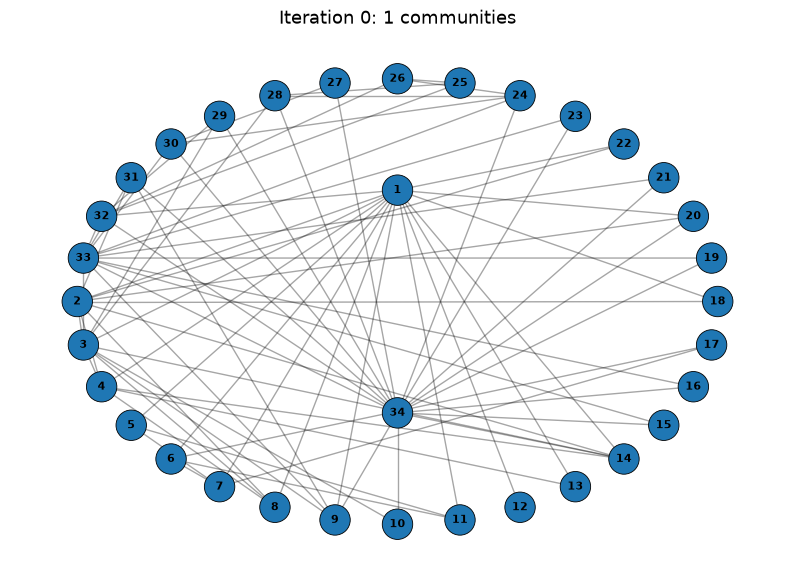

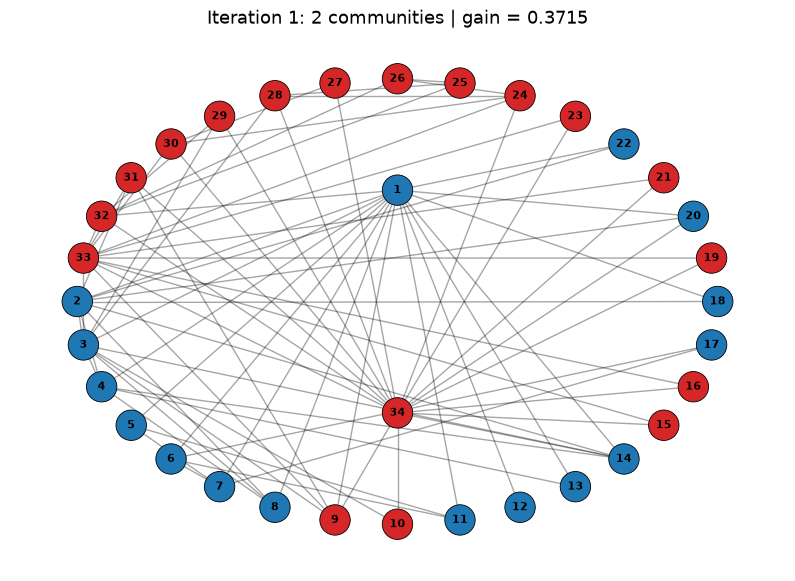

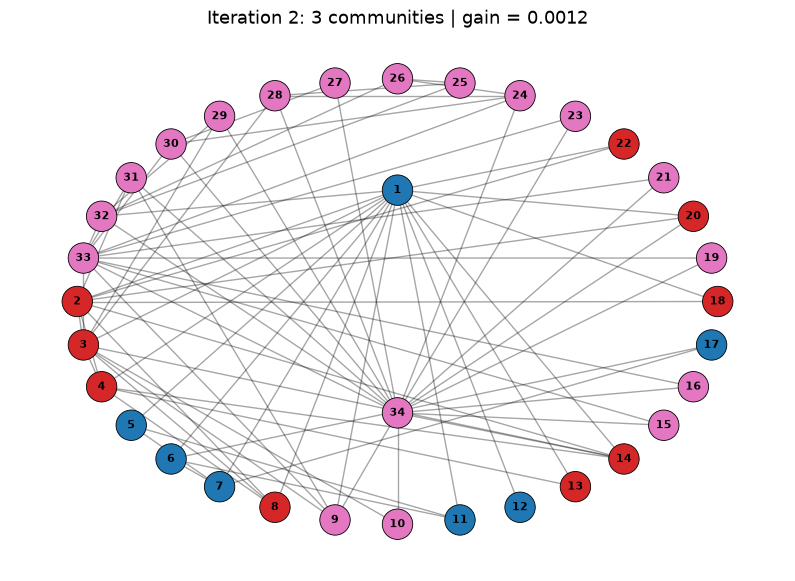

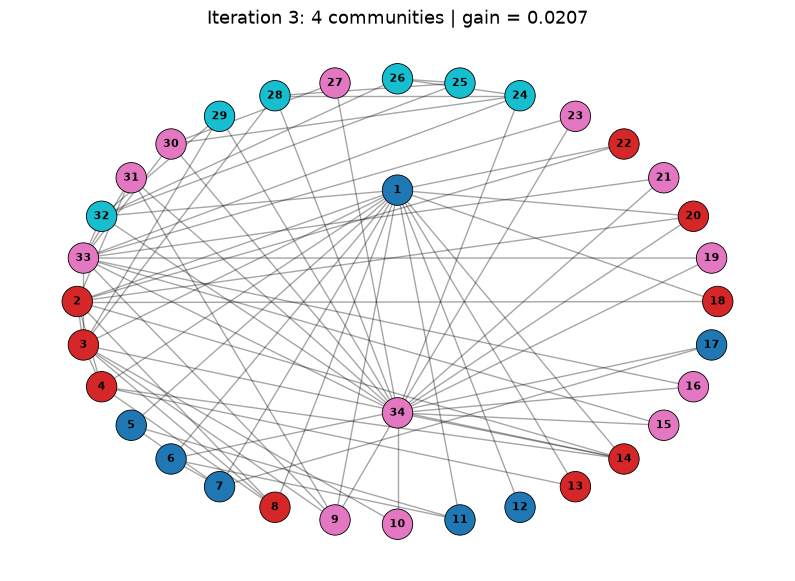

In [5]:
palette = plt.cm.tab10(np.linspace(0, 1, max(len(record['communities']) for record in split_records)))

def draw_communities(record):
    plt.figure(figsize=(10, 7))
    color_by_node = {}
    for community_id, community in enumerate(record['communities']):
        for node in community:
            color_by_node[node] = palette[community_id % len(palette)]
    colors = [color_by_node[node] for node in nodes]
    nx.draw_networkx_edges(G, layout, alpha=0.35, width=1.0)
    nx.draw_networkx_nodes(G, layout, node_color=colors, node_size=480, edgecolors='black', linewidths=0.6)
    nx.draw_networkx_labels(G, layout, font_size=8, font_weight='bold')
    title = f"Iteration {record['iteration']}: {len(record['communities'])} communities"
    if record['split'] is not None:
        title += f" | gain = {record['gain']:.4f}"
    plt.title(title)
    plt.axis('off')
    plt.show()

for record in split_records:
    draw_communities(record)

## 04 · Diagnostics — how node roles change

Metrics are evaluated on each node's current induced community at iteration 0 and after every accepted split. They are local, within-community measurements; they should not be read as changes to the original graph itself.

In [6]:
metric_names = ['degree', 'betweenness', 'closeness', 'clustering']
metric_history = {name: {} for name in metric_names}

def metrics_for_communities(communities):
    values = {name: {} for name in metric_names}
    for community in communities:
        subgraph = G.subgraph(community).copy()
        metric_functions = {
            'degree': nx.degree_centrality,
            'betweenness': nx.betweenness_centrality,
            'closeness': nx.closeness_centrality,
            'clustering': nx.clustering,
        }
        for name, function in metric_functions.items():
            values[name].update(function(subgraph))
    return values

for record in split_records:
    values = metrics_for_communities(record['communities'])
    for name in metric_names:
        metric_history[name][record['iteration']] = values[name]

final_metric_values = metrics_for_communities(final_communities)
summary = pd.DataFrame(final_metric_values).loc[nodes]
print('Final-iteration node metrics:')
display(summary.round(4))

Final-iteration node metrics:


,degree,betweenness,closeness,clustering
1,0.8333,0.3778,0.8571,0.4000
2,0.8750,0.6548,0.8889,0.2381
3,0.5000,0.0119,0.6667,0.8333
4,0.6250,0.2619,0.7273,0.5000
5,0.5000,0.0222,0.6667,0.6667
6,0.6667,0.1556,0.7500,0.5000
7,0.6667,0.1556,0.7500,0.5000
8,0.3750,0.0000,0.6154,1.0000
9,0.2727,0.0000,0.5789,1.0000
10,0.0909,0.0000,0.5238,0.0000


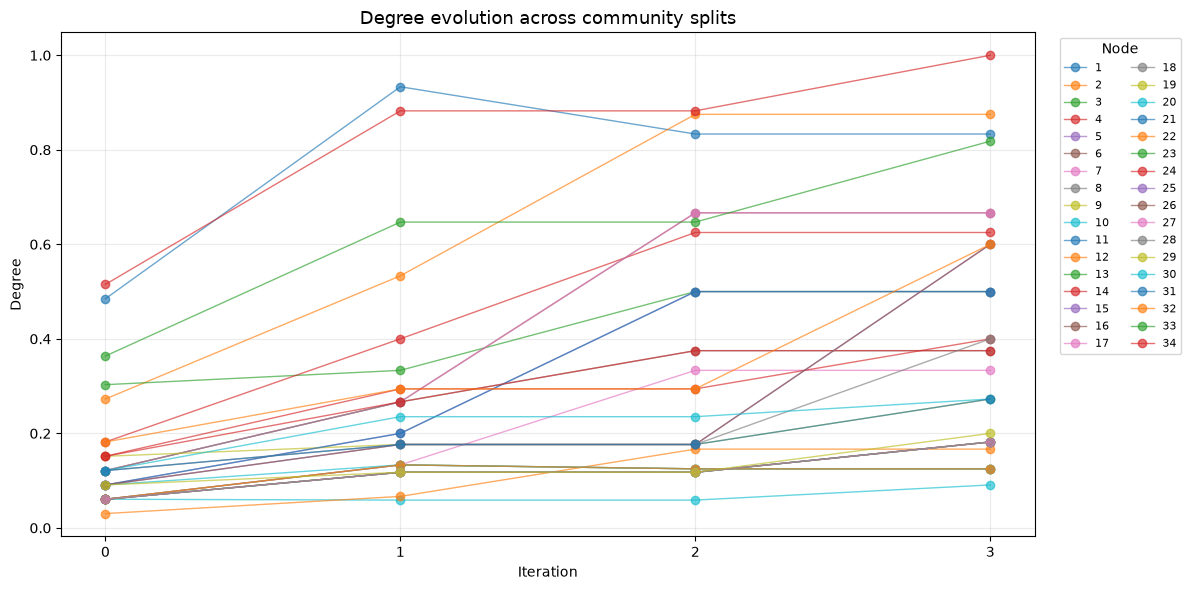

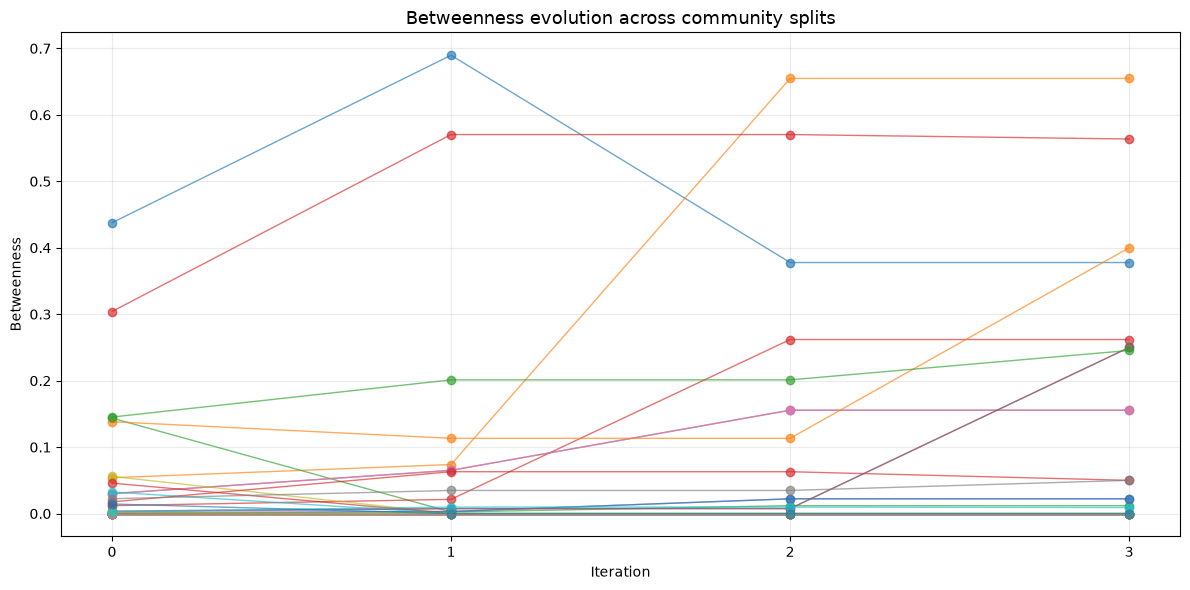

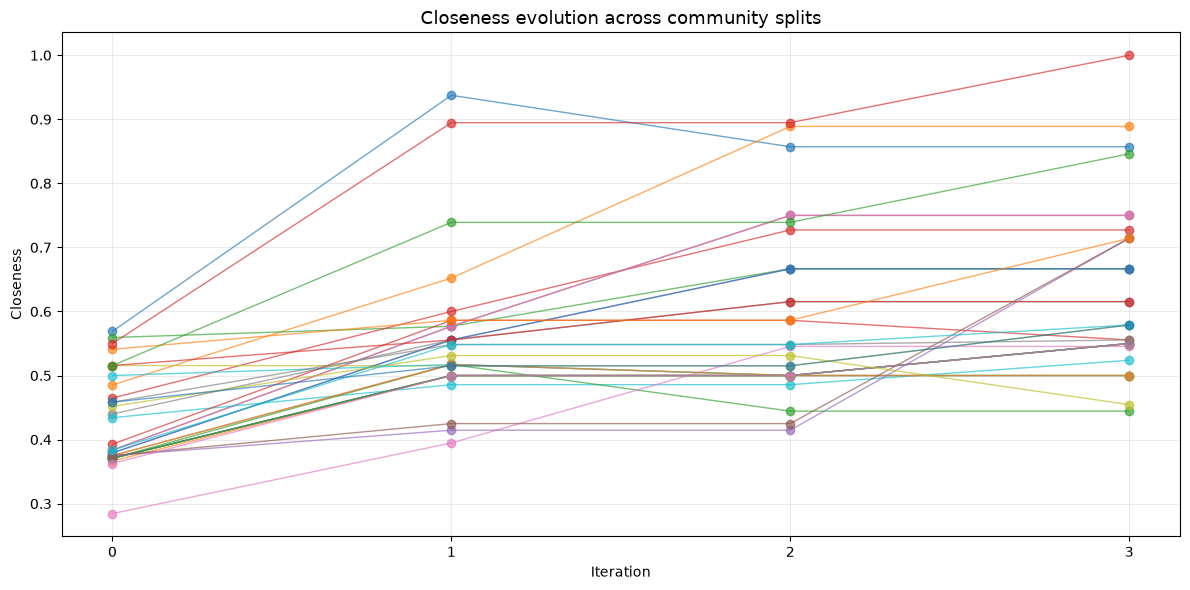

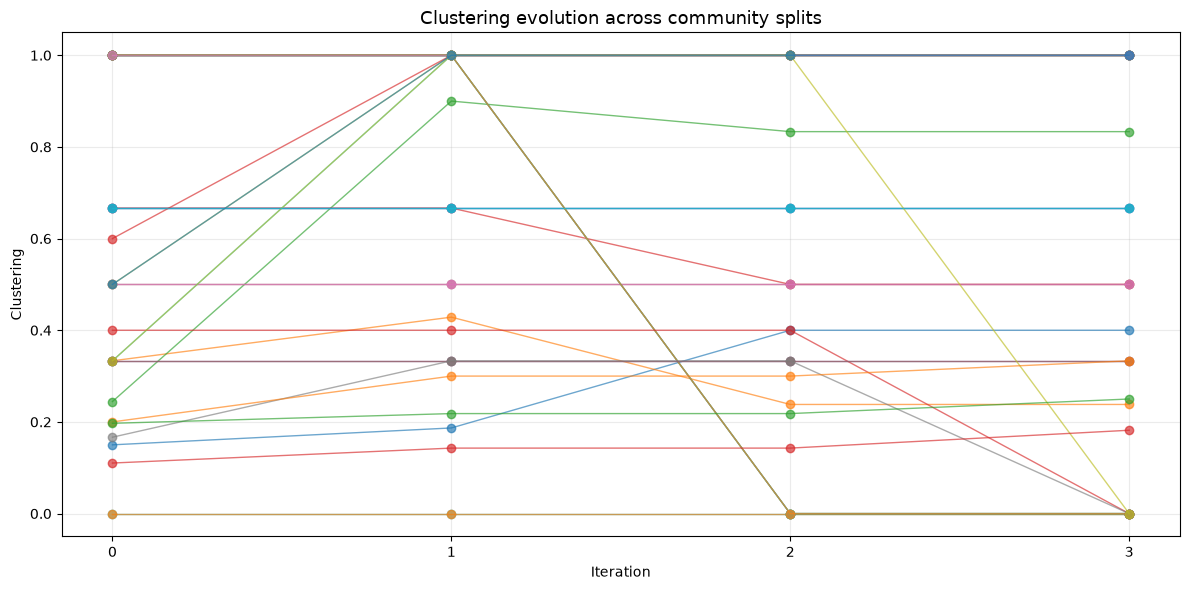

In [7]:
iterations = [record['iteration'] for record in split_records]
for name in metric_names:
    history_table = pd.DataFrame({iteration: metric_history[name][iteration] for iteration in iterations}).reindex(nodes)
    plt.figure(figsize=(12, 6))
    for node in nodes:
        plt.plot(iterations, history_table.loc[node], marker='o', linewidth=1, alpha=0.65, label=str(node))
    plt.title(f'{name.title()} evolution across community splits')
    plt.xlabel('Iteration')
    plt.ylabel(name.title())
    plt.xticks(iterations)
    plt.grid(alpha=0.25)
    if name == 'degree':
        plt.legend(title='Node', bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

## 05 · Takeaways

The first split approximates the historical separation around nodes 1 (Mr. Hi) and 34 (the administrator). Nodes that bridge dense regions can show a marked reduction in betweenness after those regions are separated into induced communities. Degree and closeness are rescaled by the smaller community denominator, while clustering can become more prominent inside cohesive local groups.

The final partition and modularity value above are the primary result; the gallery and metric histories provide the evidence for interpreting how the division develops.